Importing libraries for VGG16

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

Downloading and loading VGG model

In [2]:
model=VGG16(weights='imagenet')

model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
def predict_image(model, image_path):
  """
  Predict the class of the given image using the VGG16 model.

  Args:
      model: Pre-trained vgg16 mode.
      image_path: path of the image file.
  Return:
      Top predictions as a list of class, description, score
  """
  img=load_img(image_path, target_size=(224, 224))

  # covert image to numpy array
  img_array=img_to_array(img)

  # add a batch dimention (1, 224, 224, 3)
  img_array=np.expand_dims(img_array, axis=0)

  # pre process image for vgg 16
  img_array=preprocess_input(img_array)

  # predict the image class
  pred=model.predict(img_array)

  # decoded prediction into readable label
  decoded_pred=decode_predictions(pred, top=5)
  return decoded_pred[0]

In [20]:
import requests
def download_image(url, save_path):
  try:
    response=requests.get(url, stream= True)
    response.raise_for_status()
    with open(save_path, 'wb') as out_file:
      for chunk in response.iter_content(chunk_size=8192):
        out_file.write(chunk)
    print(f'Image downloaded successfully to {save_path}')
  except requests.exceptions.RequestException as e:
    print(f'Error downloading image: {e}')

# example
image_url="https://cdn.pixabay.com/photo/2018/04/18/08/48/vulture-3329814_1280.jpg"
output_filename='vulture.jpg'
download_image(image_url, output_filename)

Image downloaded successfully to vulture.jpg


In [22]:
# sample image prediction
my_image_path='vulture.jpg'
prediction=predict_image(model, my_image_path)

# display prediction
print('Prediction')
for i, (imagenet_id, label, score) in enumerate(prediction):
  print(f'{i+1}: {label} ({score:.2f})')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 601ms/step
Prediction
1: vulture (0.69)
2: kite (0.16)
3: bald_eagle (0.08)
4: pelican (0.04)
5: great_grey_owl (0.02)


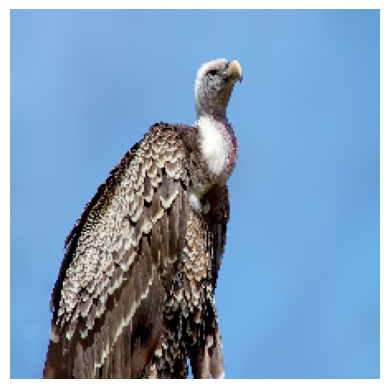

In [26]:
img=load_img('vulture.jpg', target_size=(224, 224))
plt.imshow(img)
plt.axis('off')
plt.show()

In [30]:
horse='https://s.yimg.com/fz/api/res/1.2/tnG3qV_0BPSKw6nkqXDIdg--~C/YXBwaWQ9c3JjaGRkO2ZpPWZpbGw7aD00MTI7cHhvZmY9NTA7cHlvZmY9MTAwO3E9ODA7c3M9MTt3PTM4OA--/https://i.pinimg.com/736x/5a/2b/a4/5a2ba4118e004674ca0ab0ee445f7b54.jpg'
download_image(horse, 'horse.jpg')

Image downloaded successfully to horse.jpg


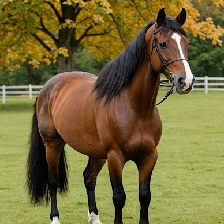

In [35]:
h=load_img('horse.jpg', target_size=(224, 224))
h

In [33]:
for i, (imagenet_id, label, score) in enumerate(predict_image(model, 'horse.jpg')):
  print(f'{i+1}: {label} ({score:.2f})')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 748ms/step
1: sorrel (0.98)
2: worm_fence (0.01)
3: horse_cart (0.01)
4: cowboy_hat (0.00)
5: plow (0.00)


In [53]:
# goat="https://s.yimg.com/fz/api/res/1.2/tnG3qV_0BPSKw6nkqXDIdg--~C/YXBwaWQ9c3JjaGRkO2ZpPWZpbGw7aD00MTI7cHhvZmY9NTA7cHlvZmY9MTAwO3E9ODA7c3M9MTt3PTM4OA--/https://i.pinimg.com/736x/5a/2b/a4/5a2ba4118e004674ca0ab0ee445f7b54.jpg"
# try:
#   response=requests.get(goat, stream= True)
#   response.raise_for_status()
#   with open('ex2.jpg', 'wb') as out_file:
#     for chunk in response.iter_content(chunk_size=8192*2):
#       out_file.write(chunk)
#       break
#   print(f'Image downloaded successfully to path')
# except requests.exceptions.RequestException as e:
#   print(f'Error downloading image: {e}')

# # this happens if we stops downloading after 2 chunks
# # go and see ex1.jpg